# ENGE707 Kaggle Competition: Controlled TTA Validation Experiment

## Cat and Dog Facial Feature Classification

This notebook performs the first low-cost improvement experiment on the existing best ResNet18 checkpoint.

It compares:

1. normal validation inference; and
2. the average of normal and horizontally flipped predictions.

No model is trained and no Kaggle test image is loaded. Horizontal-flip test-time augmentation (TTA) will be accepted only if it improves accuracy on the unchanged validation set. This isolates the effect of TTA before it is used for a Kaggle submission.

## 1. Import the Required Libraries

The notebook uses PyTorch for inference, scikit-learn for classification metrics, and Matplotlib for report figures.

In [8]:
# Imports the libraries used for the controlled prediction experiment
from pathlib import Path
from contextlib import nullcontext
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

## 2. Locate the Existing Project Artifacts

On Kaggle, every required filename is located among the attached inputs. If more than one matching project artifact is attached, the notebook stops instead of silently loading an unknown version.

In [9]:
# Finds the original checkpoint validation split and saved settings
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_unique_kaggle_file(filename, preferred_text=None):
    """Return one unambiguous Kaggle input file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if preferred_text:
        preferred = [
            path for path in matches
            if preferred_text.lower() in str(path).lower()
        ]
        if preferred:
            matches = preferred

    if len(matches) != 1:
        match_text = "\n".join(str(path) for path in matches)
        raise RuntimeError(
            f"Expected exactly one {filename}, found {len(matches)}.\n"
            f"Matches:\n{match_text}"
        )
    return matches[0]


def find_unique_image_directory(filename, split_name):
    """Locate one train or test folder containing the probe image."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    matches = [
        path for path in matches
        if split_name.lower() in {part.lower() for part in path.parent.parts}
    ]
    directories = sorted({path.parent for path in matches})
    if len(directories) != 1:
        directory_text = "\n".join(str(path) for path in directories)
        raise RuntimeError(
            f"Expected one {split_name} image folder, found "
            f"{len(directories)}.\n{directory_text}"
        )
    return directories[0]


if RUNNING_ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")
    VALIDATION_SPLIT_PATH = find_unique_kaggle_file(
        "validation_split.csv",
        preferred_text="facial-feature-project-artifacts",
    )
    PREPROCESSING_CONFIG_PATH = find_unique_kaggle_file(
        "preprocessing_config.json",
        preferred_text="facial-feature-project-artifacts",
    )
    CHECKPOINT_PATH = find_unique_kaggle_file(
        "resnet18_best.pth",
        preferred_text="facial-feature-project-artifacts",
    )

    validation_probe = pd.read_csv(
        VALIDATION_SPLIT_PATH,
        dtype={"filename": "string"},
        nrows=1,
    ).iloc[0]["filename"]
    TRAIN_IMAGE_DIR = find_unique_image_directory(
        validation_probe, "train"
    )
else:
    possible_roots = [Path.cwd(), Path.cwd().parent]
    PROJECT_ROOT = next(
        (
            folder for folder in possible_roots
            if (folder / "splits" / "validation_split.csv").exists()
        ),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("The project root could not be located.")

    VALIDATION_SPLIT_PATH = (
        PROJECT_ROOT / "splits" / "validation_split.csv"
    )
    PREPROCESSING_CONFIG_PATH = (
        PROJECT_ROOT
        / "outputs"
        / "preprocessing"
        / "preprocessing_config.json"
    )
    CHECKPOINT_PATH = PROJECT_ROOT / "models" / "resnet18_best.pth"
    TRAIN_IMAGE_DIR = PROJECT_ROOT / "data" / "train" / "train"

EXPERIMENT_DIR = PROJECT_ROOT / "outputs" / "improvements" / "tta_validation"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Environment:", "Kaggle" if RUNNING_ON_KAGGLE else "Local")
print("Validation split:", VALIDATION_SPLIT_PATH)
print("Checkpoint:", CHECKPOINT_PATH)
print("Training images:", TRAIN_IMAGE_DIR)

Environment: Kaggle
Validation split: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/validation_split.csv
Checkpoint: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/resnet18_best.pth
Training images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train/train


## 3. Load and Verify the Saved Configuration

The saved class order and ImageNet normalization values are reused exactly. The expected baseline accuracy is recorded so that the checkpoint evaluation can be compared with Notebook 5.

In [10]:
# Checks that the saved class mapping matches the validation labels
with open(PREPROCESSING_CONFIG_PATH) as config_file:
    preprocessing_config = json.load(config_file)

validation_split = pd.read_csv(
    VALIDATION_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
IMAGENET_MEAN = preprocessing_config["normalisation_mean"]
IMAGENET_STD = preprocessing_config["normalisation_std"]
NUMBER_OF_CLASSES = len(CLASS_NAMES)
EXPECTED_BASELINE_ACCURACY = 0.9965441407477222

validation_split["label_index"] = validation_split["class"].map(
    CLASS_TO_INDEX
)
if validation_split["label_index"].isna().any():
    raise ValueError("The validation split contains an unknown class.")

print("Validation images:", f"{len(validation_split):,}")
print("Classes:", CLASS_NAMES)
print("Image size:", IMAGE_SIZE)

Validation images: 12,732
Classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']
Image size: 224


## 4. Configure Reproducible Inference

Inference is deterministic. Mixed precision is used only when a CUDA GPU is available.

In [11]:
# Sets random seeds and the batch size for repeatable inference
RANDOM_SEED = 42
BATCH_SIZE = 256 if torch.cuda.is_available() else 32
NUM_WORKERS = 2 if RUNNING_ON_KAGGLE else 0
PIN_MEMORY = torch.cuda.is_available()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_MIXED_PRECISION = DEVICE.type == "cuda"

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)

Device: cuda
Batch size: 256


## 5. Recreate the Deterministic Validation Transform

The transform is identical to the transform used for the original validation evaluation: RGB conversion, square padding, bilinear resizing, tensor conversion, and ImageNet normalization. No random augmentation is used.

In [12]:
# Recreates fixed preprocessing for the original validation images
class SquarePad:
    """Pad the shorter sides without stretching the image."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        largest_side = max(width, height)
        horizontal = largest_side - width
        vertical = largest_side - height
        left = horizontal // 2
        right = horizontal - left
        top = vertical // 2
        bottom = vertical - top
        return ImageOps.expand(
            image,
            border=(left, top, right, bottom),
            fill=self.fill,
        )


validation_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

print(validation_transform)
assert "Random" not in repr(validation_transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 6. Build the Validation Loader

The validation loader preserves the saved row order. Each prediction remains linked to its image ID, filename, and true class.

In [13]:
# Creates the validation loader without changing image order
class ValidationImageDataset(Dataset):
    """Load labelled validation images for controlled inference."""

    def __init__(self, dataframe, image_directory, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_directory / row["filename"]
        with Image.open(image_path) as image:
            image = self.transform(image.convert("RGB"))

        return {
            "image": image,
            "image_id": str(row["image_id"]),
            "filename": row["filename"],
            "label": int(row["label_index"]),
        }


validation_dataset = ValidationImageDataset(
    validation_split,
    TRAIN_IMAGE_DIR,
    validation_transform,
)

loader_options = {}
if NUM_WORKERS > 0:
    loader_options = {
        "persistent_workers": True,
        "prefetch_factor": 2,
    }

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_options,
)

print("Validation batches:", len(validation_loader))

Validation batches: 50


## 7. Load and Verify the Existing Best ResNet18

The experiment starts from the exact baseline checkpoint. It does not update any weights.

In [14]:
# Loads the existing best ResNet18 without retraining it
# Reads the saved checkpoint so training does not need to be repeated
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_classes = list(checkpoint.get("class_names", []))
if checkpoint_classes != CLASS_NAMES:
    raise ValueError(
        "The checkpoint class order does not match the saved configuration."
    )

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, NUMBER_OF_CLASSES)
state_dict = {
    key.removeprefix("module."): value
    for key, value in checkpoint["model_state_dict"].items()
}
# Copies the saved weights into the matching model architecture
model.load_state_dict(state_dict)
model = model.to(DEVICE)
# Switches the model to evaluation behaviour for prediction
model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch"))
print(
    "Saved validation accuracy:",
    f"{checkpoint.get('validation_accuracy', float('nan')):.4%}",
)
print("Output classes:", model.fc.out_features)

Checkpoint epoch: 10
Saved validation accuracy: 99.6544%
Output classes: 8


## 8. Run Baseline and Horizontal-Flip TTA Together

Both methods are evaluated in the same pass through the validation loader:

- **Baseline:** predictions from the original image.
- **Flip TTA:** average the original-image logits and horizontally flipped-image logits.

Flipping the normalized tensor changes only the horizontal position of pixels; it does not change the normalization values.

In [15]:
# Compares original predictions with averaged original and flipped predictions
def mixed_precision_context():
    if USE_MIXED_PRECISION:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


prediction_rows = []
evaluation_start = time.perf_counter()

# Switches the model to evaluation behaviour for prediction
model.eval()
# Disables gradient tracking because this step does not train the model
with torch.inference_mode():
    for batch in validation_loader:
        images = batch["image"].to(
            DEVICE,
            non_blocking=PIN_MEMORY,
        )
        labels = batch["label"].cpu().numpy()

        with mixed_precision_context():
            original_logits = model(images)
            flipped_logits = model(torch.flip(images, dims=[3]))
            tta_logits = (original_logits + flipped_logits) / 2

        baseline_probabilities = torch.softmax(
            original_logits, dim=1
        ).cpu()
        tta_probabilities = torch.softmax(tta_logits, dim=1).cpu()

        baseline_confidence, baseline_predictions = (
            baseline_probabilities.max(dim=1)
        )
        tta_confidence, tta_predictions = tta_probabilities.max(dim=1)

        for values in zip(
            batch["image_id"],
            batch["filename"],
            labels.tolist(),
            baseline_predictions.tolist(),
            baseline_confidence.tolist(),
            tta_predictions.tolist(),
            tta_confidence.tolist(),
        ):
            (
                image_id,
                filename,
                true_index,
                baseline_index,
                baseline_score,
                tta_index,
                tta_score,
            ) = values
            prediction_rows.append(
                {
                    "image_id": str(image_id),
                    "filename": filename,
                    "true_index": true_index,
                    "true_class": INDEX_TO_CLASS[true_index],
                    "baseline_index": baseline_index,
                    "baseline_class": INDEX_TO_CLASS[baseline_index],
                    "baseline_confidence": baseline_score,
                    "baseline_correct": baseline_index == true_index,
                    "tta_index": tta_index,
                    "tta_class": INDEX_TO_CLASS[tta_index],
                    "tta_confidence": tta_score,
                    "tta_correct": tta_index == true_index,
                }
            )

evaluation_seconds = time.perf_counter() - evaluation_start
predictions = pd.DataFrame(prediction_rows)

print("Images evaluated:", f"{len(predictions):,}")
print("Evaluation time:", f"{evaluation_seconds:.1f} seconds")
display(predictions.head())

Images evaluated: 12,732
Evaluation time: 495.4 seconds


,image_id,filename,true_index,true_class,baseline_index,baseline_class,baseline_confidence,baseline_correct,tta_index,tta_class,tta_confidence,tta_correct
0,00013,00013.jpg,4,CatMouth,4,CatMouth,0.959473,True,4,CatMouth,0.958496,True
1,00021,00021.jpg,7,DogNose,7,DogNose,0.938477,True,7,DogNose,0.939453,True
2,00025,00025.jpg,2,CatFace,2,CatFace,0.956543,True,2,CatFace,0.958984,True
3,00034,00034.jpg,5,DogMouth,5,DogMouth,0.938477,True,5,DogMouth,0.939941,True
4,00045,00045.jpg,1,DogEye,1,DogEye,0.958984,True,1,DogEye,0.973633,True


## 9. Compare the Two Methods

Accuracy is the primary decision metric because it is also the Kaggle competition metric. Macro F1 and per-class recall are retained as supporting evidence.

In [16]:
# Counts corrected errors and new errors introduced by flipping
true_indices = predictions["true_index"].to_numpy()
baseline_indices = predictions["baseline_index"].to_numpy()
tta_indices = predictions["tta_index"].to_numpy()


def metric_row(method, predicted_indices, confidence_column):
    return {
        "method": method,
        "accuracy": accuracy_score(true_indices, predicted_indices),
        "macro_f1": f1_score(
            true_indices,
            predicted_indices,
            average="macro",
        ),
        "errors": int((predicted_indices != true_indices).sum()),
        "mean_confidence": predictions[confidence_column].mean(),
    }


comparison = pd.DataFrame(
    [
        metric_row(
            "Baseline",
            baseline_indices,
            "baseline_confidence",
        ),
        metric_row(
            "Horizontal-flip TTA",
            tta_indices,
            "tta_confidence",
        ),
    ]
)

baseline_accuracy = comparison.loc[0, "accuracy"]
tta_accuracy = comparison.loc[1, "accuracy"]
accuracy_change = tta_accuracy - baseline_accuracy

corrected_by_tta = (
    (~predictions["baseline_correct"])
    & predictions["tta_correct"]
).sum()
introduced_by_tta = (
    predictions["baseline_correct"]
    & (~predictions["tta_correct"])
).sum()
prediction_changes = (
    predictions["baseline_index"] != predictions["tta_index"]
).sum()

# Predefined decision rule: TTA must increase validation accuracy
TTA_APPROVED = bool(tta_accuracy > baseline_accuracy)

comparison["accuracy_change_vs_baseline"] = [0.0, accuracy_change]
comparison["approved_for_test_inference"] = [False, TTA_APPROVED]

display(comparison.style.format({
    "accuracy": "{:.4%}",
    "macro_f1": "{:.4f}",
    "mean_confidence": "{:.4f}",
    "accuracy_change_vs_baseline": "{:+.4%}",
}))

print("Predictions changed by TTA:", int(prediction_changes))
print("Baseline errors corrected:", int(corrected_by_tta))
print("New errors introduced:", int(introduced_by_tta))
print("TTA approved:", TTA_APPROVED)

if not np.isclose(
    baseline_accuracy,
    EXPECTED_BASELINE_ACCURACY,
    atol=1e-9,
):
    raise AssertionError(
        "The reproduced baseline does not match Notebook 5. "
        "Stop before interpreting TTA."
    )

,method,accuracy,macro_f1,errors,mean_confidence,accuracy_change_vs_baseline,approved_for_test_inference
0,Baseline,99.6544%,0.9967,44,0.9495,+0.0000%,False
1,Horizontal-flip TTA,99.6780%,0.9968,41,0.9503,+0.0236%,True


Predictions changed by TTA: 14
Baseline errors corrected: 7
New errors introduced: 4
TTA approved: True


## 10. Compare Per-Class Recall

This table checks whether an overall improvement hides a large loss for one class.

In [17]:
# Compares precision recall and F1 for the two prediction methods
baseline_report = classification_report(
    true_indices,
    baseline_indices,
    labels=list(range(NUMBER_OF_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
tta_report = classification_report(
    true_indices,
    tta_indices,
    labels=list(range(NUMBER_OF_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

per_class_comparison = pd.DataFrame(
    {
        "class": CLASS_NAMES,
        "baseline_precision": [
            baseline_report[name]["precision"] for name in CLASS_NAMES
        ],
        "baseline_recall": [
            baseline_report[name]["recall"] for name in CLASS_NAMES
        ],
        "baseline_f1": [
            baseline_report[name]["f1-score"] for name in CLASS_NAMES
        ],
        "tta_precision": [
            tta_report[name]["precision"] for name in CLASS_NAMES
        ],
        "tta_recall": [
            tta_report[name]["recall"] for name in CLASS_NAMES
        ],
        "tta_f1": [
            tta_report[name]["f1-score"] for name in CLASS_NAMES
        ],
    }
)
per_class_comparison["recall_change"] = (
    per_class_comparison["tta_recall"]
    - per_class_comparison["baseline_recall"]
)
per_class_comparison["f1_change"] = (
    per_class_comparison["tta_f1"]
    - per_class_comparison["baseline_f1"]
)

display(per_class_comparison.style.format({
    column: "{:.4f}"
    for column in per_class_comparison.columns
    if column != "class"
}))

,class,baseline_precision,baseline_recall,baseline_f1,tta_precision,tta_recall,tta_f1,recall_change,f1_change
0,CatEye,0.9953,0.9978,0.9966,0.9961,0.9989,0.9975,0.0011,0.0009
1,DogEye,0.9957,0.9948,0.9952,0.9970,0.9948,0.9959,0.0000,0.0006
2,CatFace,1.0000,0.9986,0.9993,1.0000,0.9978,0.9989,-0.0007,-0.0004
3,DogFace,1.0000,0.9991,0.9996,0.9991,0.9991,0.9991,0.0000,-0.0004
4,CatMouth,0.9957,1.0000,0.9978,0.9964,1.0000,0.9982,0.0000,0.0004
5,DogMouth,1.0000,0.9965,0.9983,1.0000,0.9974,0.9987,0.0009,0.0004
6,CatNose,0.9942,0.9899,0.9921,0.9928,0.9906,0.9917,0.0007,-0.0004
7,DogNose,0.9940,0.9957,0.9948,0.9940,0.9948,0.9944,-0.0009,-0.0004


## 11. Save Confusion Matrices and Metric Evidence

The figure and CSV files provide reproducible evidence for the report. The baseline and TTA confusion matrices use the same scale and class order.

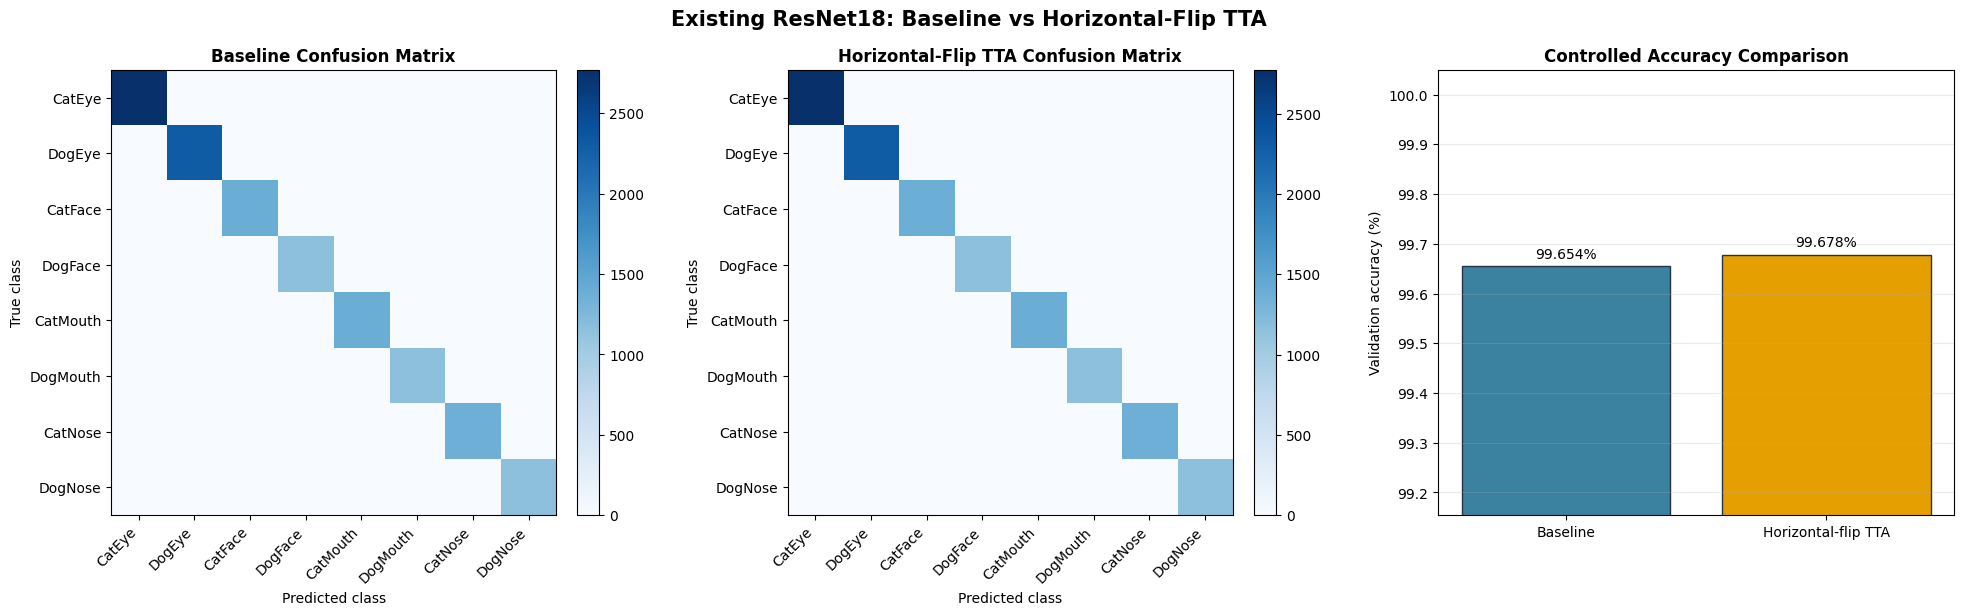

Figure: /kaggle/working/outputs/figures/figure_22_tta_validation_comparison.png


In [18]:
# Saves confusion matrices and the controlled comparison figure
baseline_matrix = confusion_matrix(
    true_indices,
    baseline_indices,
    labels=list(range(NUMBER_OF_CLASSES)),
)
tta_matrix = confusion_matrix(
    true_indices,
    tta_indices,
    labels=list(range(NUMBER_OF_CLASSES)),
)

figure_path = FIGURE_DIR / "figure_22_tta_validation_comparison.png"
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for axis, matrix, title in [
    (axes[0], baseline_matrix, "Baseline Confusion Matrix"),
    (axes[1], tta_matrix, "Horizontal-Flip TTA Confusion Matrix"),
]:
    image = axis.imshow(matrix, cmap="Blues")
    axis.set_title(title, weight="bold")
    axis.set_xticks(range(NUMBER_OF_CLASSES), CLASS_NAMES, rotation=45, ha="right")
    axis.set_yticks(range(NUMBER_OF_CLASSES), CLASS_NAMES)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)

bars = axes[2].bar(
    comparison["method"],
    comparison["accuracy"] * 100,
    color=["#3B82A0", "#E69F00"],
    edgecolor="#243447",
)
axes[2].bar_label(
    bars,
    labels=[f"{value:.3f}%" for value in comparison["accuracy"] * 100],
    padding=4,
)
lower_limit = max(0, comparison["accuracy"].min() * 100 - 0.5)
axes[2].set_ylim(lower_limit, 100.05)
axes[2].set_ylabel("Validation accuracy (%)")
axes[2].set_title("Controlled Accuracy Comparison", weight="bold")
axes[2].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Existing ResNet18: Baseline vs Horizontal-Flip TTA",
    fontsize=15,
    weight="bold",
)
fig.tight_layout()
# Saves the figure so it can be included in the report
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Saves the table as a CSV file for later notebooks or report evidence
comparison.to_csv(
    EXPERIMENT_DIR / "tta_validation_metrics.csv",
    index=False,
)
# Saves the table as a CSV file for later notebooks or report evidence
per_class_comparison.to_csv(
    EXPERIMENT_DIR / "tta_per_class_comparison.csv",
    index=False,
)
# Saves the table as a CSV file for later notebooks or report evidence
predictions.to_csv(
    EXPERIMENT_DIR / "tta_validation_predictions.csv",
    index=False,
)
# Saves the table as a CSV file for later notebooks or report evidence
pd.DataFrame(baseline_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    EXPERIMENT_DIR / "baseline_confusion_matrix.csv"
)
# Saves the table as a CSV file for later notebooks or report evidence
pd.DataFrame(tta_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    EXPERIMENT_DIR / "tta_confusion_matrix.csv"
)

print("Figure:", figure_path)

## 12. Display Predictions Changed by TTA

These examples show where flipping changes the selected class. Green titles indicate corrections; red titles indicate new errors; grey titles indicate that both methods are either correct or incorrect.

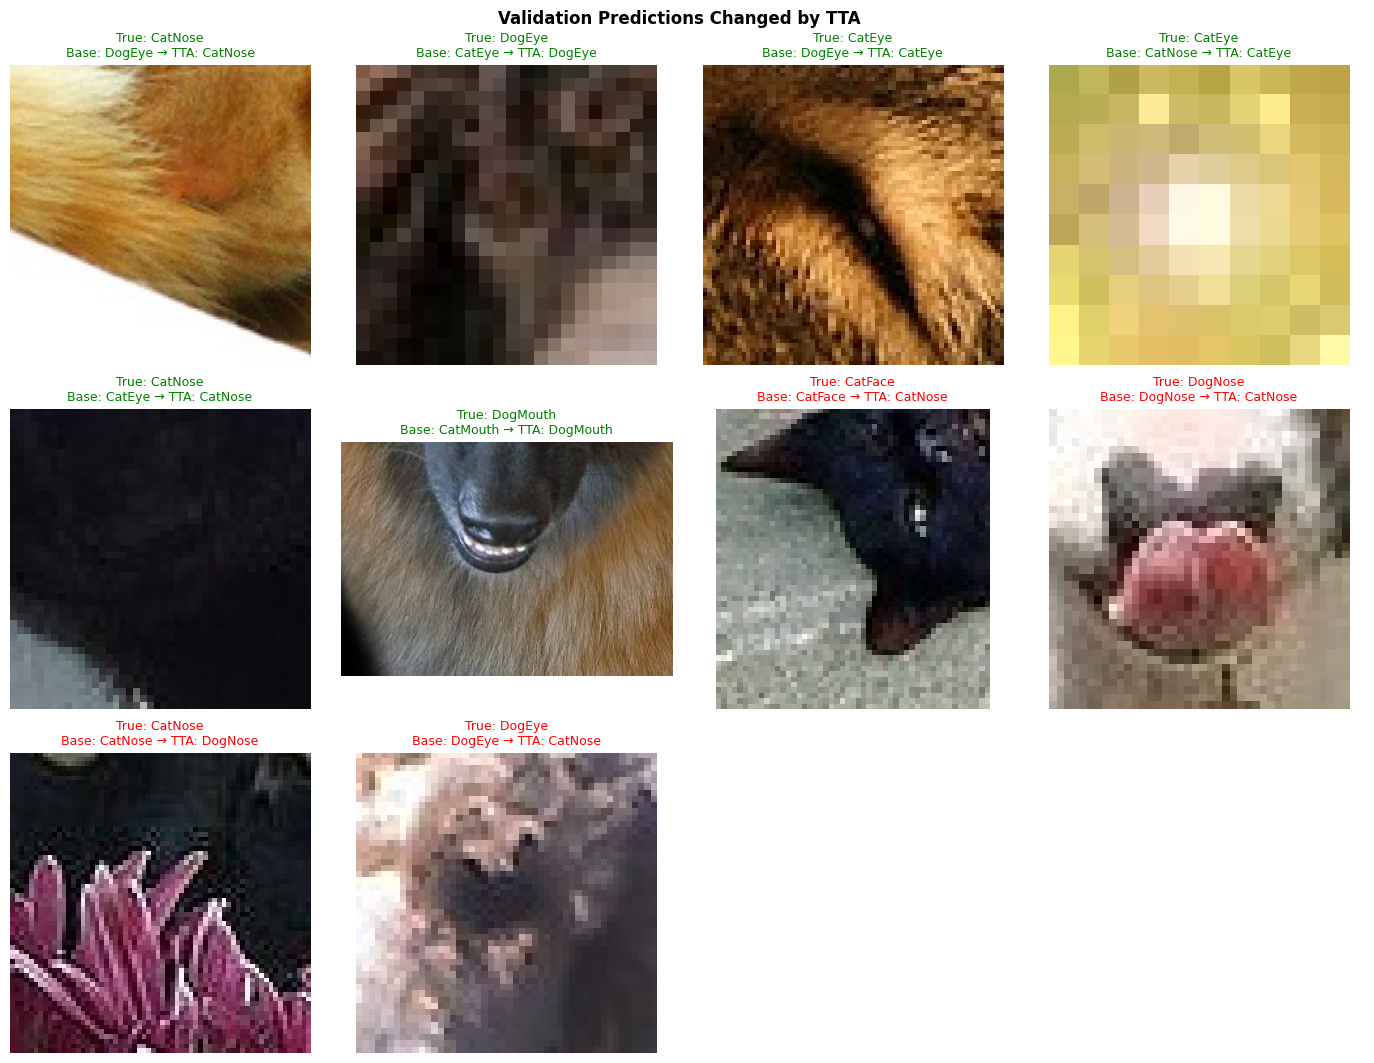

Changed-prediction figure: /kaggle/working/outputs/figures/figure_23_tta_changed_predictions.png


In [19]:
# Shows validation images whose predictions changed after flipping
changed_predictions = predictions[
    predictions["baseline_index"] != predictions["tta_index"]
].copy()
changed_predictions["outcome"] = np.select(
    [
        (~changed_predictions["baseline_correct"])
        & changed_predictions["tta_correct"],
        changed_predictions["baseline_correct"]
        & (~changed_predictions["tta_correct"]),
    ],
    ["corrected", "introduced_error"],
    default="other_change",
)
# Saves the table as a CSV file for later notebooks or report evidence
changed_predictions.to_csv(
    EXPERIMENT_DIR / "tta_changed_predictions.csv",
    index=False,
)

examples = pd.concat(
    [
        changed_predictions[changed_predictions["outcome"] == "corrected"].head(6),
        changed_predictions[
            changed_predictions["outcome"] == "introduced_error"
        ].head(6),
    ],
    ignore_index=True,
).head(12)

if len(examples) > 0:
    rows = int(np.ceil(len(examples) / 4))
    fig, axes = plt.subplots(rows, 4, figsize=(14, 3.6 * rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(TRAIN_IMAGE_DIR / row["filename"]) as image:
            axis.imshow(image.convert("RGB"))
        colour = {
            "corrected": "green",
            "introduced_error": "red",
        }.get(row["outcome"], "grey")
        axis.set_title(
            f"True: {row['true_class']}\n"
            f"Base: {row['baseline_class']} → TTA: {row['tta_class']}",
            color=colour,
            fontsize=9,
        )
        axis.axis("off")

    for axis in axes[len(examples):]:
        axis.axis("off")

    changed_figure_path = (
        FIGURE_DIR / "figure_23_tta_changed_predictions.png"
    )
    fig.suptitle("Validation Predictions Changed by TTA", weight="bold")
    fig.tight_layout()
    # Saves the figure so it can be included in the report
    fig.savefig(changed_figure_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Changed-prediction figure:", changed_figure_path)
else:
    print("TTA did not change any validation prediction.")

## 13. Record the Predefined Decision

The experiment approves TTA only when validation accuracy increases. The Kaggle score is not used to make this decision.

In [20]:
# Records whether the experiment meets the predefined acceptance rules
decision = {
    "experiment": "horizontal_flip_tta",
    "checkpoint": CHECKPOINT_PATH.name,
    "checkpoint_epoch": int(checkpoint.get("epoch", -1)),
    "validation_images": int(len(predictions)),
    "baseline_accuracy": float(baseline_accuracy),
    "tta_accuracy": float(tta_accuracy),
    "accuracy_change": float(accuracy_change),
    "baseline_macro_f1": float(comparison.loc[0, "macro_f1"]),
    "tta_macro_f1": float(comparison.loc[1, "macro_f1"]),
    "predictions_changed": int(prediction_changes),
    "baseline_errors_corrected": int(corrected_by_tta),
    "new_errors_introduced": int(introduced_by_tta),
    "decision_rule": "Approve only if TTA validation accuracy is higher",
    "tta_approved": TTA_APPROVED,
    "training_performed": False,
    "test_images_loaded": False,
    "evaluation_seconds": float(evaluation_seconds),
}

decision_path = EXPERIMENT_DIR / "tta_decision.json"
with open(decision_path, "w") as decision_file:
    json.dump(decision, decision_file, indent=4)

checks = pd.DataFrame(
    {
        "check": [
            "All validation images evaluated",
            "Baseline reproduces Notebook 5 accuracy",
            "No model training performed",
            "No Kaggle test images loaded",
            "Class order matches the checkpoint",
            "Decision was made using validation accuracy",
        ],
        "result": [
            len(predictions) == len(validation_split),
            np.isclose(
                baseline_accuracy,
                EXPECTED_BASELINE_ACCURACY,
                atol=1e-9,
            ),
            True,
            True,
            checkpoint_classes == CLASS_NAMES,
            isinstance(TTA_APPROVED, bool),
        ],
        "expected": [True] * 6,
    }
)
# Saves the table as a CSV file for later notebooks or report evidence
checks.to_csv(
    EXPERIMENT_DIR / "tta_experiment_checks.csv",
    index=False,
)
display(checks)
assert checks["result"].all()

print("Decision:", "USE TTA" if TTA_APPROVED else "KEEP BASELINE INFERENCE")
print("Decision file:", decision_path)

,check,result,expected
0,All validation images evaluated,True,True
1,Baseline reproduces Notebook 5 accuracy,True,True
2,No model training performed,True,True
3,No Kaggle test images loaded,True,True
4,Class order matches the checkpoint,True,True
5,Decision was made using validation accuracy,True,True


Decision: USE TTA
Decision file: /kaggle/working/outputs/improvements/tta_validation/tta_decision.json


## 14. Package the Experiment Evidence

The package contains only validation evidence. It does not contain a Kaggle submission because the next action depends on the recorded decision.

In [21]:
# Packages the experiment results for download
package_base = PROJECT_ROOT / "tta_validation_experiment"
package_path = shutil.make_archive(
    str(package_base),
    "zip",
    root_dir=EXPERIMENT_DIR,
)

print("Experiment package:", package_path)
print("Final decision:", "TTA approved" if TTA_APPROVED else "TTA rejected")

Experiment package: /kaggle/working/tta_validation_experiment.zip
Final decision: TTA approved


In [22]:
# Displays a download link for the saved experiment package
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/tta_validation_experiment.zip"))

/kaggle/working/tta_validation_experiment.zip